# Lithium-Ion Battery Electrothermal Modeling & State-of-Charge (SOC) Estimation
### Interactive Exploration & Verification Notebook

**Repository:** [warlord80/battery-bms-temperature-project](https://github.com/warlord80/battery-bms-temperature-project)  
**Cell Format:** Panasonic NCR18650B ($3.20\,\mathrm{Ah}$ NCA/Graphite)  
**Core Model:** 1-RC Thévenin Equivalent Circuit Model coupled to a Lumped Thermal ODE and Extended Kalman Filter (EKF) observer.

> **Research Claim:** This work develops a reduced-order electrothermal and aging-aware equivalent-circuit model for controlled sensitivity analysis of battery SOC estimation. It demonstrates behaviour under stated assumptions; it does not identify parameters from new experiments or establish a chemistry-independent degradation law.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project imports
from src.ocv import OCVModel, DEFAULT_SOC_POINTS, DEFAULT_OCV_POINTS
from src.model import BatteryCell, CellState
from src.estimators import CoulombCounter, ExtendedKalmanFilter
from src.simulation import generate_current_profile, run_single_simulation

print('All modules successfully loaded!')


All modules successfully loaded!


## 1. Thermodynamic Open-Circuit Voltage (OCV)
The equilibrium open-circuit voltage $\mathrm{OCV}(z)$ is parameterized from titration data reported by Barletta et al. (2022).  
Piecewise Cubic Hermite Interpolating Polynomials (PCHIP) guarantee strict monotonicity ($d\mathrm{OCV}/dz > 0$) without artificial numerical oscillations.

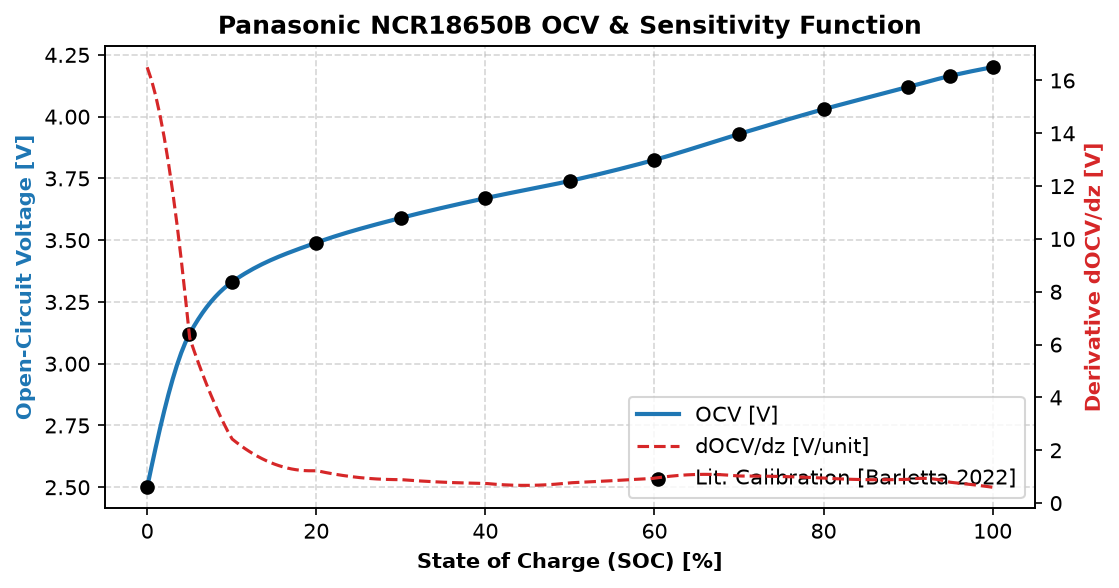

In [2]:
ocv = OCVModel()
z_fine = np.linspace(0.0, 1.0, 200)
ocv_vals = ocv.evaluate(z_fine)
docv_vals = ocv.derivative(z_fine)

fig, ax1 = plt.subplots(figsize=(8.0, 4.0))
ax2 = ax1.twinx()
p1, = ax1.plot(z_fine * 100.0, ocv_vals, color='#1f77b4', linewidth=2.0, label='OCV [V]')
p2, = ax2.plot(z_fine * 100.0, docv_vals, color='#d62728', linestyle='--', linewidth=1.5, label='dOCV/dz [V/unit]')
p3 = ax1.scatter(DEFAULT_SOC_POINTS * 100.0, DEFAULT_OCV_POINTS, color='#000000', zorder=5, label='Lit. Calibration')
ax1.set_xlabel('State of Charge (SOC) [%]', fontweight='bold')
ax1.set_ylabel('Open-Circuit Voltage [V]', color='#1f77b4', fontweight='bold')
ax2.set_ylabel('Derivative dOCV/dz [V]', color='#d62728', fontweight='bold')
ax1.set_title('Panasonic NCR18650B OCV & Sensitivity Function', fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend([p1, p2, p3], ['OCV [V]', 'dOCV/dz [V]', 'Lit. Points'], loc='lower right')
plt.show()


## 2. Arrhenius Temperature & SOH Resistance Scaling
Ohmic resistance $R_0$ scales with temperature $T$ via Arrhenius kinetics and with state of health (SOH) via degradation scaling:
$$R_0(T, \mathrm{SOH}) = R_{0,\mathrm{ref}} \exp\left[\frac{E_{a,0}}{R_g}\left(\frac{1}{T} - \frac{1}{T_{\mathrm{ref}}}\right)\right] \left[1 + \alpha_0 (1 - \mathrm{SOH})\right]$$
Higher temperatures increase ionic mobility (lowering resistance), while cell aging increases internal resistance.

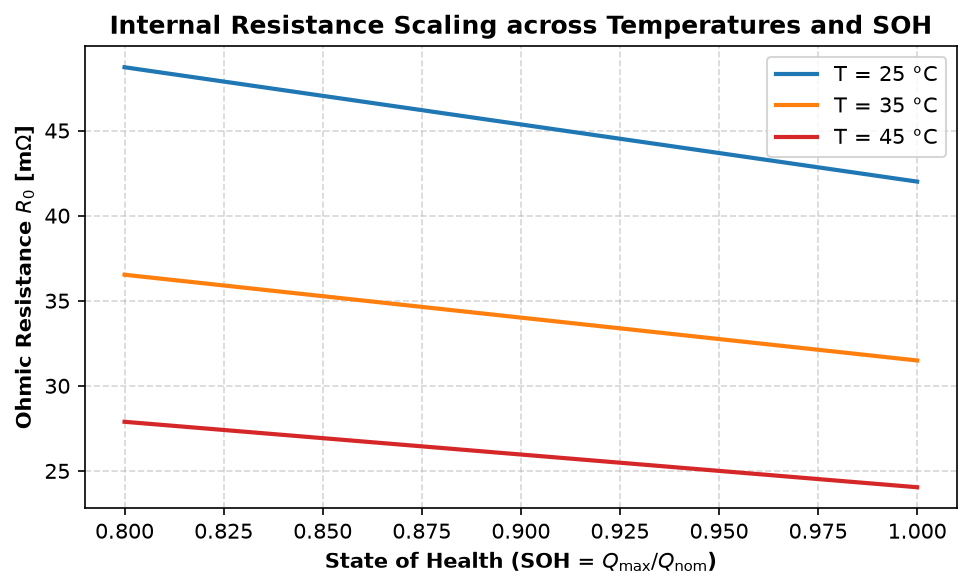

In [3]:
cell = BatteryCell()
soh_grid = np.linspace(0.80, 1.00, 100)
fig, ax = plt.subplots(figsize=(7.5, 4.0))
for t_c, col in zip([25.0, 35.0, 45.0], ['#1f77b4', '#ff7f0e', '#d62728']):
    t_k = t_c + 273.15
    r0_m = [cell.get_r0(t_k, s) * 1000.0 for s in soh_grid]
    ax.plot(soh_grid, r0_m, label=f'T = {t_c:.0f} °C', color=col, linewidth=2.0)
ax.set_xlabel('State of Health (SOH)', fontweight='bold')
ax.set_ylabel('Ohmic Resistance [mOhm]', fontweight='bold')
ax.set_title('Internal Resistance Scaling across Temperatures and SOH', fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()
plt.show()


## 3. Dynamic Simulation: Coulomb Counting vs. Extended Kalman Filter
We simulate a 1-hour dynamic drive cycle at $25\,^\circ\mathrm{C}$ with an intentional **$-15\%$ initial SOC error**:
- **Ground Truth Initial SOC:** $0.80$ ($80\%$)
- **Estimator Initial Guess:** $0.65$ ($65\%$)
- **Open-loop Baseline (Coulomb Counting):** Assumes nominal $3.20\,\mathrm{Ah}$.
- **Closed-loop Observer (EKF):** Uses terminal voltage feedback $V_{t,\mathrm{meas}}$ and analytical Jacobians.

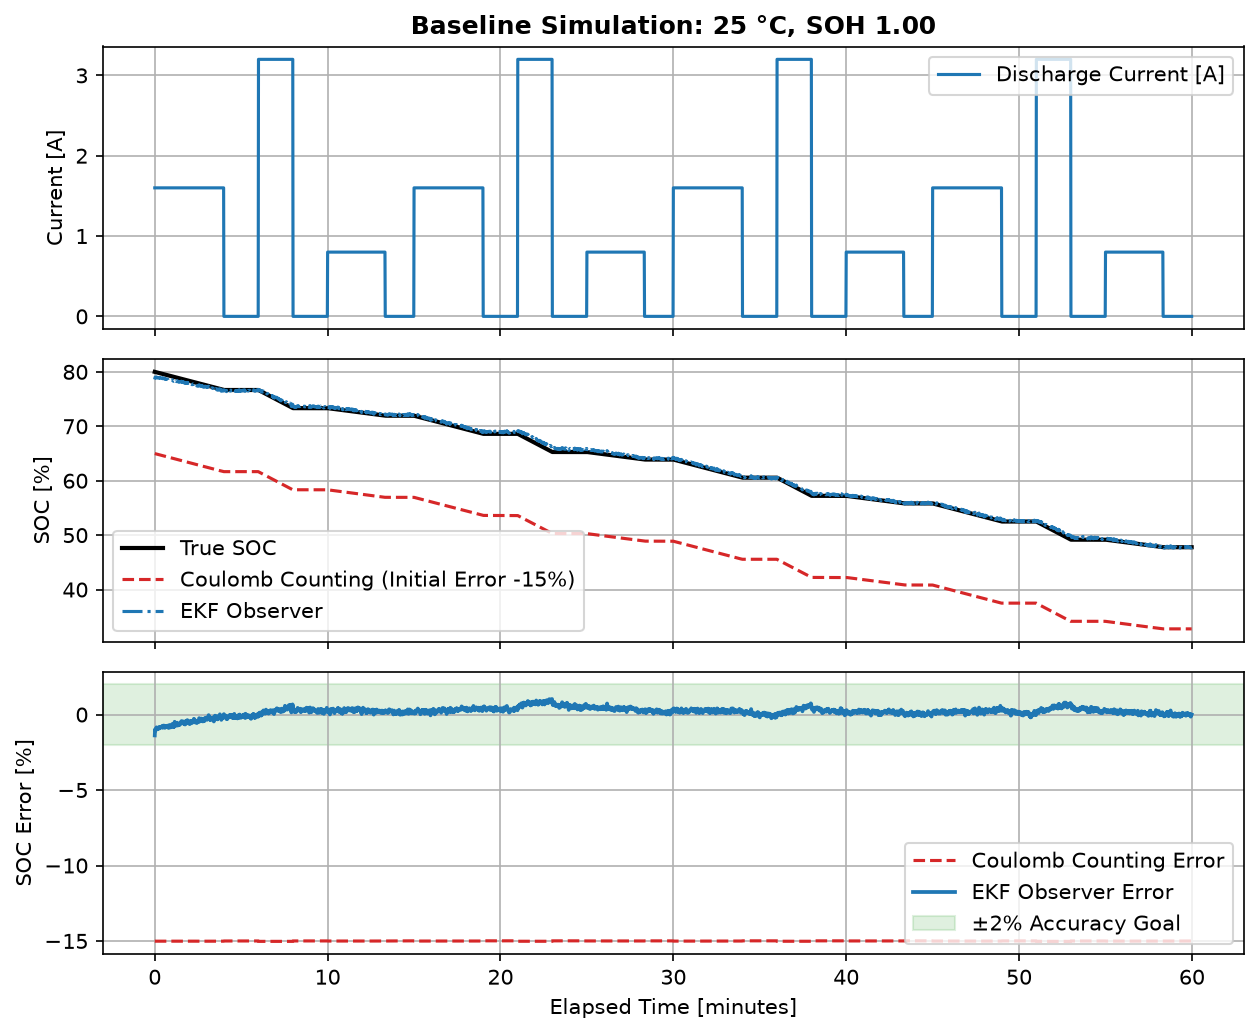

--- Estimation Accuracy Metrics ---
Coulomb Counting RMSE: 15.00% | Final Error: -15.00%
Extended Kalman Filter RMSE: 0.34% | Final Error: 0.00%
EKF Recovery Time (|error| <= 2%): 0.0 seconds


In [4]:
init_state = CellState(soc=0.80, vp=0.0, temperature_k=298.15, q_max=3.20, soh=1.0, neq=0.0)
cc = CoulombCounter(soc_init=0.65)
ekf = ExtendedKalmanFilter(ocv_model=ocv, soc_init=0.65)
profile = generate_current_profile('dynamic_pulse', duration_s=3600.0, dt=1.0)

df_sim, m = run_single_simulation(
    cell=cell, coulomb_counter=cc, ekf=ekf,
    current_profile=profile, dt=1.0, t_amb_k=298.15,
    true_init_state=init_state, random_seed=42
)

# Display metrics
print('--- Estimation Accuracy Metrics ---')
print(f'Coulomb Counting RMSE: {m["soc_rmse_cc_pct"]:.2f}% | Final Error: {m["final_error_cc_pct"]:.2f}%')
print(f'Extended Kalman Filter RMSE: {m["soc_rmse_ekf_pct"]:.2f}% | Final Error: {m["final_error_ekf_pct"]:.2f}%')
print(f'EKF Recovery Time (|error| <= 2%): {m["recovery_time_2pct_s"]} seconds')


## 4. Parameter Sensitivity & Tornado Analysis
To answer **Research Question 4** (*Which factor has the largest effect: ambient temperature, load profile, capacity fade, or resistance growth?*), we inspect the Tornado sensitivity ranking across 75 Monte Carlo evaluations.

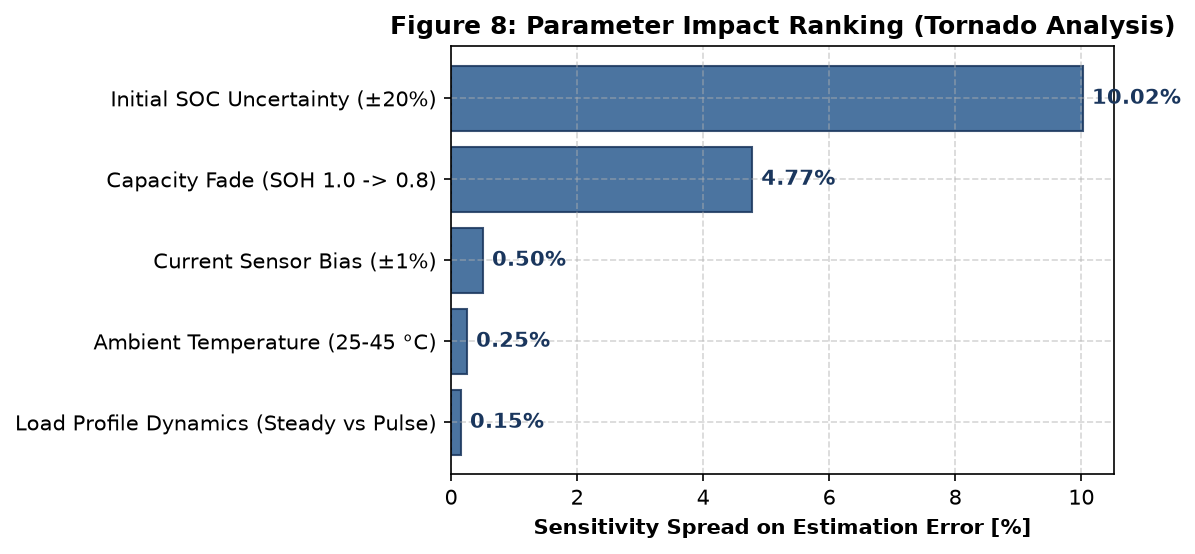

Factor,Impact_Range_Pct,Domain
Load Profile Dynamics (Steady vs Pulse),0.150680,Operating Profile
Ambient Temperature (25-45 °C),0.248111,Environment
Current Sensor Bias (±1%),0.500139,Instrumentation
Capacity Fade (SOH 1.0 -> 0.8),4.772945,Cell Aging
Initial SOC Uncertainty (±20%),10.018903,State Initialization


In [5]:
tornado_path = Path('../results/tables/sensitivity_tornado_ranking.csv')
if not tornado_path.exists():
    tornado_path = Path('results/tables/sensitivity_tornado_ranking.csv')
df_tornado = pd.read_csv(tornado_path)
df_tornado


## 5. Summary & Reproducibility

- **Full Reproduction Command:** `python run_pipeline.py` (executes all tests, 36 scenarios, and 75 Monte Carlo robustness runs in < 90s).
- **Full Academic Manuscript:** See [`report/main.md`](../report/main.md) for the 12-page manuscript.
- **One-Page Outreach Summary:** See [`report/professor_outreach_summary.md`](../report/professor_outreach_summary.md) for graduate application emails.